In [1]:
import numpy as np 
from matplotlib import pyplot as plt

For this exercise, I did all the tasks using the revised and thinning poisson simulation at the same time and used inverse distribution fucntion
to simulate random Poisson at first (I didn't read the question very carefully until I'm almost finished with my code and I absolutely don't want to touch it after)

In [2]:
rate = (0.2,0.9,0.5,0.6,1.0,0.6,0.5)
times = (6,8,12,15,17,19,24)
total_time = 60*24   

Inverse Distribution Function of Poisson Process
$-\frac{log(1-u)}{\lambda}$

In [3]:
# Revised
def revised_simulation(rate,times,total_time):
    boundaries = [min(60*t, total_time) for t in times]
    total_interval = 0.0
    last = 0.0
    index = 0
    intervals = []
    while total_interval < total_time and index < len(rate):
        u = np.random.uniform(0,1)
        delta_t = -np.log(1-u)/rate[index]
        
        if total_interval + delta_t  >= boundaries[index]:
            total_interval = boundaries[index]
            index = index + 1
        else: 
            total_interval += delta_t
            intervals.append(total_interval - last)
            last = total_interval
    return intervals
    

In [4]:
# Thinning 
def thinning_simulation(rate, times, total_time):
    rate = np.asarray(rate)
    boundaries = 60*np.asarray(times)
    max_rate = rate.max()
    t = 0.0
    last = 0.0
    intervals = []
    while True:
        u = np.random.uniform(0, 1)
        t += -np.log(1-u)/max_rate 
        if t >= total_time:
            break
        index = np.searchsorted(boundaries, t, side='right')
        if np.random.uniform(0, 1) < rate[index]/max_rate:
            intervals.append(t - last)
            last = t
    return intervals

## i) Plot the average number of cars that arrived at (and obviously left) the crossing per minute over the period of 24 hours.

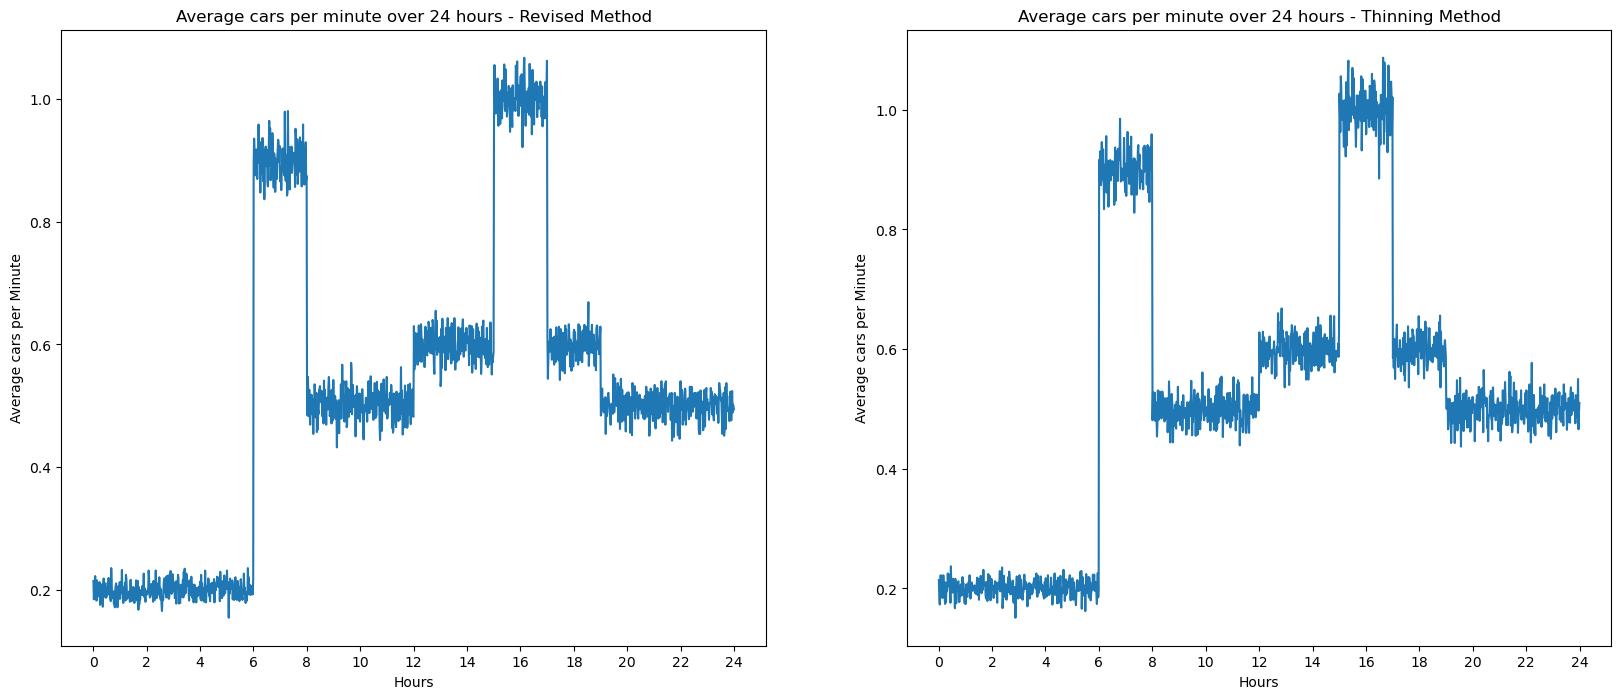

In [5]:
no_process = 1000
all_arrivals_revised = []
all_arrivals_thinning = []

no_cars_revised = []
no_cars_thinning = []

first_arrival_revised = []
first_arrival_thinning = []
for i in range(no_process):
    arrival_revised = revised_simulation(rate, times, total_time)
    arrival_thinning = thinning_simulation(rate, times, total_time)

    all_arrivals_revised.append(list(np.cumsum(arrival_revised)))
    all_arrivals_thinning.append(list(np.cumsum(arrival_thinning)))

    no_cars_revised.append(len(arrival_revised))
    no_cars_thinning.append(len(arrival_thinning))

    first_arrival_revised.append(arrival_revised[0])
    first_arrival_thinning.append(arrival_thinning[0])

# arrival times are in minutes -> count arrivals per 1-minute bin, averaged over simulations
bins = np.arange(0, total_time + 1, 1)
arrivals_flat_revised = np.concatenate(all_arrivals_revised)
arrivals_flat_thinning = np.concatenate(all_arrivals_thinning)
avg_per_min_revised = np.histogram(arrivals_flat_revised, bins=bins)[0] / no_process
avg_per_min_thinning = np.histogram(arrivals_flat_thinning, bins=bins)[0] / no_process

hours = (bins[:-1] + 0.5) / 60     
fig,axs = plt.subplots(1,2,figsize=(20,8))

axs[0].plot(hours, avg_per_min_revised,linestyle = '-')
axs[0].set_xlabel("Hours")
axs[0].set_ylabel("Average cars per Minute")
axs[0].set_title("Average cars per minute over 24 hours - Revised Method")
axs[0].set_xticks(range(0, 25, 2))
            
axs[1].plot(hours, avg_per_min_thinning, linestyle = '-')
axs[1].set_xlabel("Hours")
axs[1].set_ylabel("Average cars per Minute")
axs[1].set_title("Average cars per minute over 24 hours - Thinning Method")
axs[1].set_xticks(range(0, 25, 2))

## (ii) (w=2) Also plot the cumulative number of cars that arrived per minute over the period of 24 hours


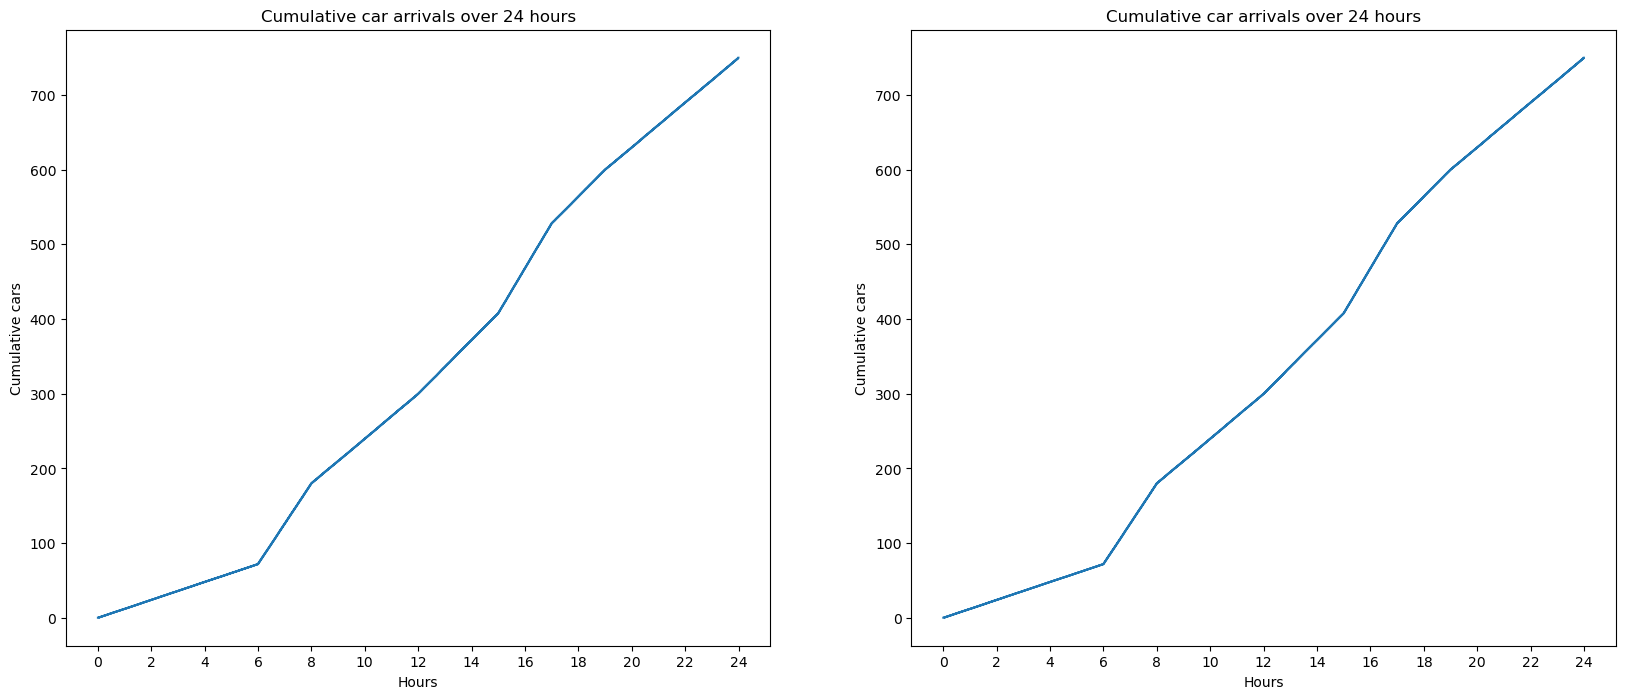

In [6]:
cumulative_revised = np.cumsum(avg_per_min_revised)
cumulative_thinning = np.cumsum(avg_per_min_thinning)

fig,axs = plt.subplots(1,2,figsize=(20,8))

axs[0].plot(hours, cumulative_thinning, drawstyle='steps-post')
axs[0].set_xlabel("Hours")
axs[0].set_ylabel("Cumulative cars")
axs[0].set_title("Cumulative car arrivals over 24 hours")
axs[0].set_xticks(range(0, 25, 2))

axs[1].plot(hours, cumulative_thinning, drawstyle='steps-post')
axs[1].set_xlabel("Hours")
axs[1].set_ylabel("Cumulative cars")
axs[1].set_title("Cumulative car arrivals over 24 hours")
axs[1].set_xticks(range(0, 25, 2))

## (iii) (w=1) print the average number of cars that arrived in one day and

In [7]:
print(f'Average number of cars that arrived in one day - Revised method: {np.average(no_cars_revised):.2f}')
print(f'Average number of cars that arrived in one day - Thinning method: {np.average(no_cars_thinning):.2f}')

Average number of cars that arrived in one day - Revised method: 749.91
Average number of cars that arrived in one day - Thinning method: 749.67


## (iv) (w=1) the average time when the first car arrived.

In [8]:
print(f'Average time when the first car arrived - Revised method: {np.average(first_arrival_revised):.2f} minutes')
print(f'Average time when the first car arrived - Thinning method: {np.average(first_arrival_thinning):.2f} minutes')

Average time when the first car arrived - Revised method: 5.06 minutes
Average time when the first car arrived - Thinning method: 5.00 minutes
